In [1]:
import csv
import hashlib
import json
import re
import sys
import unicodedata
from collections import Counter
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits

from atividades.analisar_colunas import CAMPOS, DADOS, POR_CAMPO, hierarquias
from atividades.representacoes import ENTRADAS, representacao

SAIDA = Path("datasets/preparados_02")
ALVO = "parte_atingida_classe"
DESCONHECIDO = "[desconhecido]"
nomes = """agente data_acidente cbo cbo_descricao cid cid_descricao cnae cnae_descricao
emitente especie_beneficio filiacao obito municipio_empregador natureza_lesao origem_cadastro
parte_atingida sexo tipo uf_acidente uf_empregador data_afastamento data_despacho data_acidente_2
data_nascimento data_emissao tipo_empregador cnpj_cei""".split()
versoes = {p: version(p) for p in ["numpy", "pandas", "scikit-learn", "scipy", "pyarrow", "matplotlib", "threadpoolctl"]}

In [2]:
arquivos = []
partes = []
for mes in range(1, 7):
    caminho = DADOS / "CAT_2026" / f"D.SDA.PDA.005.CAT.2026{mes:02}.csv"
    with caminho.open(encoding="latin-1", newline="") as arquivo:
        leitor = csv.reader(arquivo, delimiter=";")
        assert tuple(" ".join(s.split()) for s in next(leitor)) == CAMPOS, caminho
        contagem = Counter()
        for numero, linha in enumerate(leitor, start=2):
            assert len(linha) == len(nomes), (caminho.name, numero)
            contagem["total"] += 1
            if linha[18].strip().casefold() == "ceará":
                contagem["acidente CE"] += 1
                contagem["empregador DF entre CE"] += linha[19].strip() == "Distrito Federal"
                contagem["empregador CE entre CE"] += linha[19].strip() == "Ceará"
                partes.append([*linha, caminho.name, numero])
        arquivos.append({"arquivo": caminho.name, **contagem})
inventario = pd.DataFrame(arquivos).set_index("arquivo")
display(inventario)
ce = pd.DataFrame(partes, columns=[*nomes, "arquivo", "linha"])
del partes

def ler_data(serie):
    return pd.to_datetime(serie.str.strip(), format="%d/%m/%Y", errors="coerce")

primeira, segunda = (ler_data(ce[c]) for c in ["data_acidente", "data_acidente_2"])
conflito = primeira.notna() & segunda.notna() & primeira.ne(segunda)
ocorrencia = primeira.combine_first(segunda).mask(conflito)
semestre = ocorrencia.between("2026-01-01", "2026-06-30")
problemas_data = ce.loc[ocorrencia.isna(), ["arquivo", "linha"]].copy()
problemas_data["motivo"] = np.where(conflito[ocorrencia.isna()], "datas divergentes", "sem data válida")
display(pd.Series({
    "UF do acidente Ceará": len(ce),
    "Datas do acidente divergentes": conflito.sum(),
    "Duas datas inválidas": (primeira.isna() & segunda.isna()).sum(),
    "Uma data válida": (primeira.isna() ^ segunda.isna()).sum(),
    "Data válida fora do semestre": (ocorrencia.notna() & ~semestre).sum(),
}, name="Registros").to_frame())
recorte = ce.loc[semestre].copy()
recorte["ocorrencia"] = ocorrencia[semestre]
recorte["emissao"] = ler_data(recorte["data_emissao"])

def identificar(valores):
    texto = json.dumps(valores, ensure_ascii=False, separators=(",", ":"))
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

recorte["id_registro"] = [identificar(r) for r in recorte[nomes].itertuples(index=False, name=None)]
origens = recorte[["id_registro", "arquivo", "linha"]].copy()
bruta = recorte.drop_duplicates(nomes).set_index("id_registro").sort_index()
assert bruta.index.is_unique and len(bruta) == origens.id_registro.nunique()
assert not origens.duplicated(["arquivo", "linha"]).any()
dev = bruta.ocorrencia.lt("2026-06-01")
display(pd.Series({
    "Linhas no recorte": len(recorte),
    "Combinações distintas": len(bruta),
    "Cópias adicionais": len(recorte) - len(bruta),
    "Desenvolvimento": dev.sum(),
    "Teste de junho": (~dev).sum(),
}, name="Registros").to_frame())

,total,acidente CE,empregador DF entre CE,empregador CE entre CE
arquivo,,,,
D.SDA.PDA.005.CAT.202601.csv,53595,798,732,0
D.SDA.PDA.005.CAT.202602.csv,65622,1021,945,1
D.SDA.PDA.005.CAT.202603.csv,72021,1194,1095,1
D.SDA.PDA.005.CAT.202604.csv,74363,1201,1123,4
D.SDA.PDA.005.CAT.202605.csv,214049,3722,3462,4
D.SDA.PDA.005.CAT.202606.csv,140513,2359,2188,3


,Registros
UF do acidente Ceará,10295
Datas do acidente divergentes,0
Duas datas inválidas,0
Uma data válida,0
Data válida fora do semestre,1446


,Registros
Linhas no recorte,8849
Combinações distintas,7201
Cópias adicionais,1648
Desenvolvimento,5988
Teste de junho,1213


In [3]:
texto = bruta[nomes].apply(lambda s: s.str.split().str.join(" ").str.casefold())
limpo = texto.copy()
motivos = pd.DataFrame(index=bruta.index)
perfil = []
for posicao, campo in enumerate(nomes):
    s = texto[campo]
    motivo = pd.Series("", index=s.index)
    for valor, rotulo in [("", "vazio"), ("{ñ class}", "não classificado"), ("00/00/0000", "data zerada")]:
        motivo.loc[s.eq(valor)] = rotulo
    motivo.loc[s.isin(POR_CAMPO.get(posicao, set()))] = "marcador do campo"
    if campo.startswith("data_"):
        motivo.loc[motivo.eq("") & ler_data(s).isna()] = "data inválida"
    motivos[campo] = motivo
    limpo[campo] = s.mask(motivo.ne(""))
    perfil.append({"posição": posicao + 1, "campo": campo, "valores informados": limpo.loc[dev, campo].nunique(),
                   "ausentes": limpo.loc[dev, campo].isna().sum(),
                   **motivo[dev & motivo.ne("")].value_counts().to_dict()})
display(pd.DataFrame(perfil).fillna(0).set_index("posição"))
pares = []
for campo in ["cbo", "cnae", "cid"]:
    descricao = campo + "_descricao"
    juntos = limpo.loc[dev, [campo, descricao]].dropna()
    links = juntos.drop_duplicates()
    pares.append({"campo": campo, "linhas com ambos": len(juntos),
                  "códigos com vários textos": links.groupby(campo)[descricao].nunique().gt(1).sum(),
                  "textos com vários códigos": links.groupby(descricao)[campo].nunique().gt(1).sum()})
display(pd.DataFrame(pares).set_index("campo"))
prazo = (bruta.emissao - bruta.ocorrencia).dt.days
display(pd.DataFrame([{
    "Linhas no recorte": len(recorte),
    "Duas datas do acidente idênticas": recorte.data_acidente.eq(recorte.data_acidente_2).sum(),
}]))
display(pd.DataFrame([{
    "Prazo mínimo (dias)": prazo[dev].min(),
    "Prazo mediano (dias)": prazo[dev].median(),
    "Prazo máximo (dias)": prazo[dev].max(),
    "Emissões anteriores ao acidente": prazo[dev].lt(0).sum(),
    "Emissões ausentes": prazo[dev].isna().sum(),
}], index=["Desenvolvimento"]))

,campo,valores informados,ausentes,não classificado,marcador do campo,data zerada
posição,,,,,,
1,agente,187,119,119.0,0.0,0.0
2,data_acidente,151,0,0.0,0.0,0.0
3,cbo,576,1,0.0,1.0,0.0
4,cbo_descricao,487,918,918.0,0.0,0.0
5,cid,845,0,0.0,0.0,0.0
6,cid_descricao,842,10,10.0,0.0,0.0
7,cnae,288,200,0.0,200.0,0.0
8,cnae_descricao,182,202,202.0,0.0,0.0
9,emitente,5,8,8.0,0.0,0.0


,linhas com ambos,códigos com vários textos,textos com vários códigos
campo,,,
cbo,5069,0,0
cnae,5786,0,30
cid,5978,0,0


,Linhas no recorte,Duas datas do acidente idênticas
0,8849,8849


,Prazo mínimo (dias),Prazo mediano (dias),Prazo máximo (dias),Emissões anteriores ao acidente,Emissões ausentes
Desenvolvimento,0,5.0,191,0,0


In [4]:
def referencia(arquivo, **opcoes):
    return pd.read_csv(DADOS / arquivo, dtype=str, keep_default_na=False,
                       **({"sep": ";", "encoding": "latin-1"} | opcoes))

def mapa_unico(chaves, rotulos):
    pares = pd.DataFrame({"chave": chaves.str.strip(), "rótulo": rotulos.str.strip()}).drop_duplicates()
    assert pares.chave.ne("").all() and pares.chave.is_unique
    return pares.set_index("chave")["rótulo"]

cbo_ref = referencia("CBOs/CBO2002 - Ocupacao.csv")
cnae_ref = referencia("cnae20.csv")
cid_ref = pd.concat([referencia("CIDs/CID-10-CATEGORIAS.CSV").rename(columns={"CAT": "chave"}),
                     referencia("CIDs/CID-10-SUBCATEGORIAS.CSV").rename(columns={"SUBCAT": "chave"})])
familias, divisoes = hierarquias()
mapas = {"cbo": mapa_unico(cbo_ref.CODIGO, cbo_ref.TITULO),
         "cnae": mapa_unico(cnae_ref.cod_classe.str.replace(r"\D", "", regex=True).str[:4], cnae_ref.denom_classe),
         "cid": mapa_unico(cid_ref.chave, cid_ref.DESCRICAO)}
auditoria = bruta[["ocorrencia", "emissao", "parte_atingida"]].copy()
for campo in ["cbo", "cnae", "cid"]:
    chave = limpo[campo]
    if campo == "cid":
        chave = chave.str.upper().str.replace(".", "", regex=False)
    rotulo = chave.map(mapas[campo])
    auditoria[campo + "_rotulo"] = rotulo
    auditoria[campo + "_status"] = np.select([chave.isna(), rotulo.isna()], ["sem chave", "sem correspondência"], "associada")

def prefixo(texto):
    base = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]+", " ", base).strip()

agentes = referencia("agente_causador_acidente_trabalho.csv", sep=",", encoding="utf-8")[["codigo", "descricao"]].drop_duplicates()
assert agentes.codigo.is_unique
descricoes = agentes.descricao.map(prefixo)
associacoes = []
for valor in limpo.agente.dropna().unique():
    chave = prefixo(valor)
    opcoes = agentes[descricoes.str.startswith(chave)] if chave else agentes.iloc[:0]
    status = {0: "sem correspondência", 1: "associada"}.get(len(opcoes), "ambígua")
    codigo, descricao = opcoes.iloc[0] if len(opcoes) == 1 else (None, None)
    associacoes.append((valor, status, codigo, descricao))
ref_agente = pd.DataFrame(associacoes, columns=["agente", "agente_status", "agente_codigo", "agente_rotulo"]).set_index("agente")
for coluna in ref_agente:
    auditoria[coluna] = limpo.agente.map(ref_agente[coluna])
auditoria["agente_status"] = auditoria.agente_status.fillna("sem chave")
for campo in nomes:
    if motivos[campo].ne("").any():
        auditoria["motivo_" + campo] = motivos[campo].replace("", pd.NA)
auditoria["motivo_alvo"] = motivos.parte_atingida.replace("", pd.NA)
assert auditoria.index.equals(bruta.index)
cobertura = pd.DataFrame({campo: auditoria.loc[dev, campo + "_status"].value_counts()
                          for campo in ["cbo", "cnae", "cid", "agente"]}).fillna(0).astype(int)
assert cobertura.sum().eq(dev.sum()).all()
display(cobertura)

base = limpo[["agente", "tipo", "cbo", "cnae"]].copy()
base["cbo_familia"] = base.cbo.map(familias)
base["cnae_divisao"] = base.cnae.map(divisoes)
assert not base.eq(DESCONHECIDO).any().any()
base = base.fillna(DESCONHECIDO)
base[ALVO] = limpo.parte_atingida
classes_mes = pd.crosstab(base[ALVO].fillna("[alvo ausente]"), bruta.ocorrencia.dt.month)
assert classes_mes.to_numpy().sum() == len(bruta)
display(classes_mes)
display(pd.DataFrame([{
    "Classes no desenvolvimento": base.loc[dev, ALVO].nunique(),
    "Classes com menos de 10 registros no desenvolvimento": base.loc[dev, ALVO].value_counts().lt(10).sum(),
    "Alvos ausentes no semestre": base[ALVO].isna().sum(),
}]))

,cbo,cnae,cid,agente
ambígua,0,0,0,581
associada,5986,5786,5988,4947
sem chave,1,200,0,119
sem correspondência,1,2,0,341


ocorrencia,1,2,3,4,5,6
parte_atingida_classe,,,,,,
abdome (inclusive or,4,2,5,7,4,3
antebraco (entre o p,16,13,13,16,23,18
aparelho circulatori,0,0,0,0,1,0
aparelho digestivo,1,1,0,2,0,0
aparelho genito-urin,0,0,0,2,1,0
aparelho respiratori,1,10,8,3,5,4
artelho,4,5,4,9,5,5
articulacao do torno,52,54,62,57,68,44
boca (inclusive labi,1,5,3,5,5,8


,Classes no desenvolvimento,Classes com menos de 10 registros no desenvolvimento,Alvos ausentes no semestre
0,42,6,0


In [5]:
papeis = []
resumo_cortes = []
for mes in (3, 4, 5, 6):
    corte = pd.Timestamp(2026, mes, 1)
    anteriores = bruta.ocorrencia.lt(corte)
    disponiveis = bruta.emissao.ge(bruta.ocorrencia) & bruta.emissao.lt(corte)
    avaliadas = bruta.ocorrencia.dt.month.eq(mes)
    treino = base.index[anteriores & disponiveis & base[ALVO].notna()]
    avaliacao = base.index[avaliadas & base[ALVO].notna()]
    assert treino.intersection(avaliacao).empty and bruta.loc[treino, "emissao"].lt(corte).all()
    for papel, ids in [("treino", treino), ("teste" if mes == 6 else "validacao", avaliacao)]:
        papeis.append(pd.DataFrame({"mes": mes, "papel": papel, "id_registro": ids}))
    resumo_cortes.append({"mês": mes, "acidentes anteriores": anteriores.sum(), "treino": len(treino),
                          "avaliação": len(avaliacao), "ainda sem emissão válida no corte": (anteriores & ~disponiveis).sum()})
particoes = pd.concat(papeis, ignore_index=True)
assert not particoes.duplicated(["mes", "id_registro"]).any()
display(pd.DataFrame(resumo_cortes).set_index("mês"))
display(pd.DataFrame([{
    "Acidentes de junho": (~dev).sum(),
    "Emissões após 30 de junho": ((~dev) & bruta.emissao.gt("2026-06-30")).sum(),
}]))

,acidentes anteriores,treino,avaliação,ainda sem emissão válida no corte
mês,,,,
3,2217,1816,1264,401
4,3481,3004,1202,477
5,4683,4203,1305,480
6,5988,5565,1213,423


,Acidentes de junho,Emissões após 30 de junho
0,1213,262


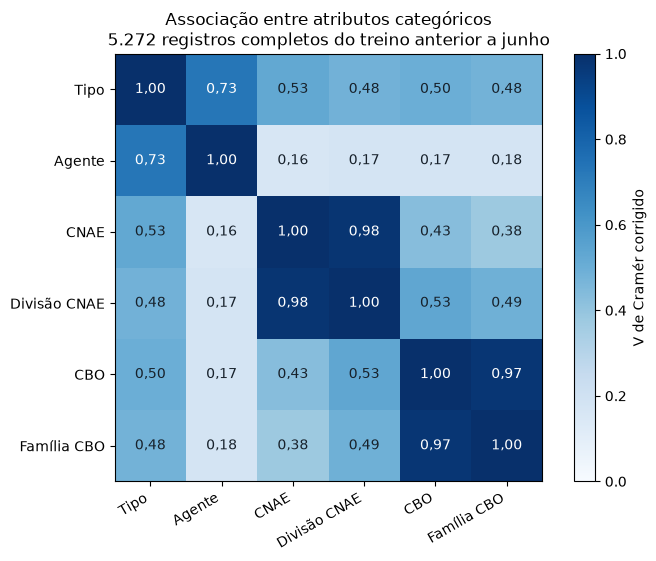

,Tipo,Agente,CNAE,Divisão CNAE,CBO,Família CBO
Tipo,1.000,0.730,0.526,0.482,0.498,0.477
Agente,0.730,1.000,0.159,0.173,0.173,0.177
CNAE,0.526,0.159,1.000,0.980,0.431,0.376
Divisão CNAE,0.482,0.173,0.980,1.000,0.534,0.490
CBO,0.498,0.173,0.431,0.534,1.000,0.973
Família CBO,0.477,0.177,0.376,0.490,0.973,1.000


In [6]:
from itertools import combinations
from scipy.stats import chi2_contingency

figuras = Path("figuras/atividade_02")
figuras.mkdir(parents=True, exist_ok=True)
ids_treino = particoes.loc[particoes.mes.eq(6) & particoes.papel.eq("treino"), "id_registro"]
rotulos = {"tipo": "Tipo", "agente": "Agente", "cnae": "CNAE", "cnae_divisao": "Divisão CNAE",
           "cbo": "CBO", "cbo_familia": "Família CBO"}
atributos = base.loc[ids_treino, list(rotulos)].replace(DESCONHECIDO, pd.NA).dropna().rename(columns=rotulos)

def v_cramer_corrigido(a, b):
    tabela = pd.crosstab(a, b)
    linhas, colunas = tabela.shape
    n = tabela.to_numpy().sum()
    if min(linhas, colunas) < 2:
        return np.nan
    qui_quadrado = chi2_contingency(tabela, correction=False).statistic
    phi2 = max(0, qui_quadrado / n - (linhas - 1) * (colunas - 1) / (n - 1))
    graus = min((linhas - 1) * (n - linhas), (colunas - 1) * (n - colunas)) / (n - 1)
    return np.sqrt(phi2 / graus) if graus > 0 else np.nan

matriz = pd.DataFrame(np.eye(len(rotulos)), index=atributos.columns, columns=atributos.columns)
for a, b in combinations(atributos.columns, 2):
    matriz.loc[a, b] = matriz.loc[b, a] = v_cramer_corrigido(atributos[a], atributos[b])

fig, ax = plt.subplots(figsize=(7.4, 5.5), layout="constrained")
escala = ax.imshow(matriz, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(matriz)), matriz.columns, rotation=30, ha="right")
ax.set_yticks(range(len(matriz)), matriz.index)
for (i, j), valor in np.ndenumerate(matriz.to_numpy()):
    ax.text(j, i, f"{valor:.2f}".replace(".", ","), ha="center", va="center",
            color="white" if valor > .55 else "#17212b")
ax.set_title(f"Associação entre atributos categóricos\n{len(atributos):,} registros completos do treino anterior a junho".replace(",", "."))
fig.colorbar(escala, ax=ax, label="V de Cramér corrigido")
fig.savefig(figuras / "associacao_atributos.png", dpi=150)
plt.show()
display(matriz.round(3))

In [7]:
from sklearn.metrics import precision_recall_fscore_support

resultados, por_classe, selecoes, componentes, cargas = [], [], [], [], []
projecao = None
with threadpool_limits(limits=1):
    for mes in (3, 4, 5):
        dobra = particoes[particoes.mes.eq(mes)]
        tr = base.loc[dobra.loc[dobra.papel.eq("treino"), "id_registro"]]
        va = base.loc[dobra.loc[dobra.papel.eq("validacao"), "id_registro"]]
        y, observado = tr[ALVO], va[ALVO]
        classes = sorted(observado.unique())
        for nome in ["Classe mais frequente", *ENTRADAS]:
            if nome == "Classe mais frequente":
                previsto = np.repeat(y.mode().iloc[0], len(va))
                dimensao, segundos = 0, 0.0
            else:
                campos = ENTRADAS[nome]
                modelo = Pipeline([("entrada", representacao(nome)),
                                   ("classificar", LogisticRegression(C=1.0, solver="lbfgs", max_iter=500, tol=1e-5))])
                inicio = perf_counter()
                modelo.fit(tr[campos], y)
                segundos = perf_counter() - inicio
                previsto = modelo.predict(va[campos])
                dimensao = modelo["classificar"].n_features_in_
                assert modelo["classificar"].n_iter_.max() < 500
                entrada = modelo["entrada"]
                nomes_colunas = entrada["codificar"].get_feature_names_out()
                if nome == "Informação mútua":
                    filtro = entrada["reduzir"]
                    for coluna, pontuacao in zip(nomes_colunas[filtro.get_support()], filtro.scores_[filtro.get_support()]):
                        selecoes.append((mes, coluna, pontuacao))
                if nome == "PCA 95%":
                    pca = entrada["reduzir"]
                    acumulada = np.cumsum(pca.explained_variance_ratio_)
                    assert acumulada[-1] >= .95 and (len(acumulada) == 1 or acumulada[-2] < .95)
                    for numero, (pesos, proporcao, total) in enumerate(zip(pca.components_, pca.explained_variance_ratio_, acumulada), 1):
                        ordem = np.argsort(-np.abs(pesos))[:3]
                        componentes.append((mes, numero, proporcao, total))
                        cargas.extend((mes, numero, nomes_colunas[i], pesos[i]) for i in ordem)
                    if mes == 5:
                        xy = entrada.transform(va[campos])[:, :2]
                        principais = y.value_counts().head(3).index
                        projecao = pd.DataFrame(xy, columns=["CP1", "CP2"], index=va.index)
                        projecao["classe"] = observado.where(observado.isin(principais), "demais classes")
            acuracia = accuracy_score(observado, previsto)
            f1 = f1_score(observado, previsto, labels=classes, average="macro", zero_division=0)
            resultados.append((mes, nome, dimensao, acuracia, f1, segundos))
            _, recall, f1s, n = precision_recall_fscore_support(observado, previsto, labels=classes, zero_division=0)
            por_classe.extend((mes, nome, classe, int(suporte), r, f)
                              for classe, suporte, r, f in zip(classes, n, recall, f1s))

medidas = pd.DataFrame(resultados, columns=["mês", "versão", "colunas", "acurácia", "F1 macro", "segundos"])
medias = medidas.groupby("versão", sort=False)[["acurácia", "F1 macro", "segundos"]].mean()
larguras = medidas.pivot(index="versão", columns="mês", values="colunas").add_prefix("colunas mês ")
display(medias.join(larguras).round(4))
display(medidas.pivot(index="versão", columns="mês", values="F1 macro").round(4))
detalhes = pd.DataFrame(por_classe, columns=["mês", "versão", "classe", "n", "recall", "F1"])
classes_freq = base.loc[dev, ALVO].value_counts().head(6).index
display(detalhes[detalhes.classe.isin(classes_freq)].pivot_table(index="classe", columns="versão", values="F1").round(3))

,acurácia,F1 macro,segundos,colunas mês 3,colunas mês 4,colunas mês 5
versão,,,,,,
Classe mais frequente,0.1929,0.0081,0.0000,0,0,0
Completa,0.2792,0.0792,0.4368,676,848,938
Tipo e agente,0.2844,0.0614,0.2434,147,172,181
"Tipo, agente e divisão",0.2925,0.0771,0.3043,206,237,247
Com família CBO,0.2821,0.0785,0.3556,399,470,510
Sem agente,0.2499,0.0405,0.2116,62,68,69
Informação mútua,0.2799,0.0798,2.7984,338,424,469
PCA 95%,0.2770,0.0788,1.1880,333,391,413


mês,3,4,5
versão,,,
Classe mais frequente,0.0077,0.0083,0.0084
Com família CBO,0.0724,0.0792,0.0839
Completa,0.0720,0.0829,0.0827
Informação mútua,0.0714,0.0825,0.0856
PCA 95%,0.0698,0.0819,0.0846
Sem agente,0.0408,0.0379,0.0428
Tipo e agente,0.0529,0.0635,0.0677
"Tipo, agente e divisão",0.0722,0.0811,0.0779


versão,Classe mais frequente,Com família CBO,Completa,Informação mútua,PCA 95%,Sem agente,Tipo e agente,"Tipo, agente e divisão"
classe,,,,,,,,
articulacao do torno,0.000,0.270,0.223,0.233,0.230,0.016,0.172,0.294
dedo,0.323,0.540,0.538,0.536,0.535,0.434,0.523,0.544
joelho,0.000,0.141,0.152,0.147,0.148,0.068,0.088,0.170
mao (exceto punho ou,0.000,0.086,0.054,0.060,0.067,0.000,0.094,0.061
partes multiplas - a,0.000,0.257,0.251,0.237,0.236,0.226,0.225,0.277
pe (exceto artelhos),0.000,0.265,0.264,0.270,0.264,0.152,0.274,0.256


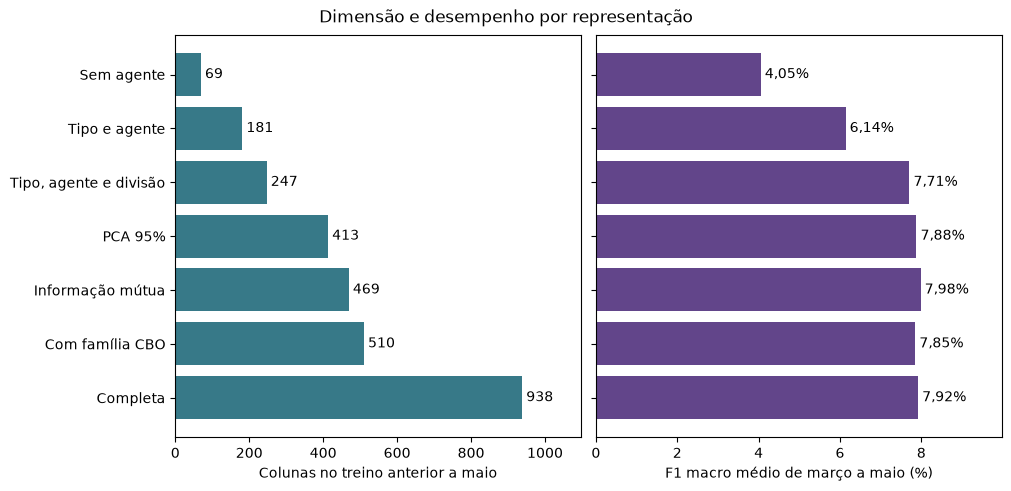

In [8]:
comparadas = medidas.loc[medidas["versão"].ne("Classe mais frequente")]
largura_maio = comparadas.loc[comparadas["mês"].eq(5)].set_index("versão")["colunas"].sort_values()
f1_medio = 100 * comparadas.groupby("versão")["F1 macro"].mean().reindex(largura_maio.index)
fig, (ax_dim, ax_f1) = plt.subplots(1, 2, figsize=(10, 4.8), sharey=True, layout="constrained")
posicoes = np.arange(len(largura_maio))
barras = ax_dim.barh(posicoes, largura_maio, color="#377988")
ax_dim.set_yticks(posicoes, largura_maio.index)
ax_dim.invert_yaxis()
ax_dim.bar_label(barras, padding=3)
ax_dim.set(xlabel="Colunas no treino anterior a maio", xlim=(0, largura_maio.max() * 1.17))
barras = ax_f1.barh(posicoes, f1_medio, color="#62458a")
ax_f1.bar_label(barras, labels=[f"{v:.2f}%".replace(".", ",") for v in f1_medio], padding=3)
ax_f1.set(xlabel="F1 macro médio de março a maio (%)", xlim=(0, f1_medio.max() * 1.25))
fig.suptitle("Dimensão e desempenho por representação")
fig.savefig(figuras / "dimensao_desempenho.png", dpi=150)
plt.show()

In [9]:
selecao = pd.DataFrame(selecoes, columns=["mês", "coluna", "informação mútua"])
estabilidade = selecao.groupby("coluna").agg(dobras=("mês", "nunique"), media=("informação mútua", "mean"))
display(estabilidade.query("dobras == 3").nlargest(12, "media").round(4))
conjuntos = {mes: set(grupo.coluna) for mes, grupo in selecao.groupby("mês")}
sobreposicao = []
for a, b in [(3, 4), (4, 5), (3, 5)]:
    comuns = conjuntos[a] & conjuntos[b]
    reunidas = conjuntos[a] | conjuntos[b]
    sobreposicao.append({"Mês A": a, "Mês B": b, "Indicadores em comum": len(comuns),
                         "Sobreposição (%)": round(100 * len(comuns) / len(reunidas), 1)})
display(pd.DataFrame(sobreposicao))
display(pd.DataFrame([{"Indicadores comuns aos três meses": len(set.intersection(*conjuntos.values()))}]))

,dobras,media
coluna,,
tipo_típico,3,0.1085
tipo_doença,3,0.1061
tipo_trajeto,3,0.0833
cnae_8660,3,0.0500
cbo_322205,3,0.0417
agente_agente infeccioso ou,3,0.0389
agente_[desconhecido],3,0.0371
agente_escada permanente cu,3,0.0338
agente_chao - superficie ut,3,0.0312


,Mês A,Mês B,Indicadores em comum,Sobreposição (%)
0,3,4,329,76.0
1,4,5,404,82.6
2,3,5,327,68.1


,Indicadores comuns aos três meses
0,323


,mês,componente,individual,acumulada
332,3,333,0.0003,0.9502
723,4,391,0.0003,0.9502
1136,5,413,0.0002,0.9502


,mês,componente,individual,acumulada
0,3,1,0.1155,0.1155
1,3,2,0.0533,0.1688
333,4,1,0.1156,0.1156
334,4,2,0.0526,0.1682
724,5,1,0.1166,0.1166
725,5,2,0.0498,0.1664


,mês,componente,indicador,peso
2172,5,1,tipo_típico,0.698
2173,5,1,tipo_trajeto,-0.639
2174,5,1,"agente_motocicleta, motonet",-0.135
2175,5,2,cbo_322205,0.694
2176,5,2,cnae_8660,0.479
2177,5,2,cnae_8610,0.355


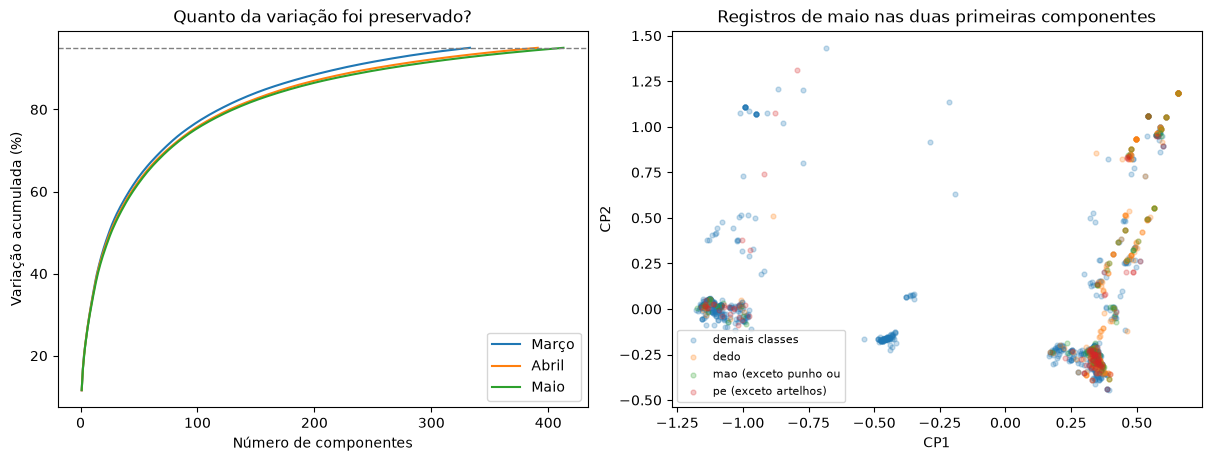

In [10]:
variancia = pd.DataFrame(componentes, columns=["mês", "componente", "individual", "acumulada"])
contribuicoes = pd.DataFrame(cargas, columns=["mês", "componente", "indicador", "peso"])
display(variancia.groupby("mês").tail(1).round(4))
display(variancia[variancia.componente.le(2)].round(4))
display(contribuicoes.query("`mês` == 5 and componente <= 2").round(3))
fig, (esq, direita) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for mes, grupo in variancia.groupby("mês"):
    esq.plot(grupo.componente, grupo.acumulada * 100, label={3: "Março", 4: "Abril", 5: "Maio"}[mes])
esq.axhline(95, color="gray", ls="--", lw=1)
esq.set(xlabel="Número de componentes", ylabel="Variação acumulada (%)", title="Quanto da variação foi preservado?")
esq.legend()
for classe, grupo in sorted(projecao.groupby("classe"), key=lambda par: par[0] != "demais classes"):
    direita.scatter(grupo.CP1, grupo.CP2, s=12, alpha=.25, label=classe)
direita.set(xlabel="CP1", ylabel="CP2", title="Registros de maio nas duas primeiras componentes")
direita.legend(fontsize=8)
plt.show()

In [11]:
SAIDA.mkdir(parents=True, exist_ok=True)
listas = sorted(set(c for campos in ENTRADAS.values() for c in campos))
assert set(base) == set([*listas, ALVO])
assert base.index[dev].intersection(base.index[~dev]).empty
for nome, tabela in [("desenvolvimento", base[dev].reset_index()), ("teste_junho", base[~dev].reset_index()),
                     ("particoes", particoes), ("origens", origens), ("auditoria", auditoria.reset_index()),
                     ("datas_sem_particao", problemas_data)]:
    caminho = SAIDA / (nome + ".parquet")
    tabela.to_parquet(caminho, index=False)
    pd.testing.assert_frame_equal(tabela.reset_index(drop=True), pd.read_parquet(caminho), check_dtype=False)
for nome, tabela in [("comparacao", medidas), ("metricas_por_classe", detalhes),
                     ("indicadores_selecionados", selecao), ("variancia_pca", variancia),
                     ("principais_pesos_pca", contribuicoes)]:
    tabela.to_parquet(SAIDA / (nome + ".parquet"), index=False)
manifesto = {"alvo": ALVO, "id": "id_registro", "entradas": ENTRADAS, "categoria_ausente": DESCONHECIDO,
             "normalizacao": "espaços internos e externos padronizados, caixa uniforme; preservar categorias truncadas e múltiplas",
             "avaliacao": "meses 3, 4, 5 para validação; mês 6 para teste reservado",
             "versoes": versoes, "python": sys.version.split()[0],
             "preparacao": "atividades.representacoes.representacao(nome); ajustar em cada treino"}
with (SAIDA / "manifesto.json").open("w", encoding="utf-8") as arquivo:
    json.dump(manifesto, arquivo, ensure_ascii=False, indent=2)
    arquivo.write("\n")